# Proyecto Integrador de Ciencia de Datos e IA — Entregable 1
## Planteamiento del problema, ficha técnica y Análisis Exploratorio de Datos (EDA)

**Universidad de La Salle — Maestría en Inteligencia Artificial — Ciencia de Datos**
Docente: Fabián Camilo Castro Riveros

**Dataset:** *Medical Appointment No Shows* (Kaggle, usuario `joniarroba`), archivo `KaggleV2-May-2016.csv`.

Este cuaderno ejecuta de principio a fin el EDA exigido en la Fase 1: análisis univariado, bivariado y multivariado, pruebas χ² y diagnóstico de calidad de datos. No se imputa ni se elimina ningún registro: las decisiones de limpieza se documentan aquí y se aplican en la Fase 2.

In [4]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

BASE = Path('.')
DATA = BASE
FIGS = BASE / 'figs'
FIGS.mkdir(exist_ok=True)
RESULTADOS = {}

# Se usa el archivo oficial de Kaggle si está en /data; si no, la copia espejo.
candidatos = [DATA / 'KaggleV2-May-2016.csv', DATA / 'KaggleV2-May-2016_mirror.csv']
RUTA = next(p for p in candidatos if p.exists())
print('Archivo usado:', RUTA.name)
RESULTADOS['archivo'] = RUTA.name

Archivo usado: KaggleV2-May-2016.csv


## 1. Carga y estructura del dataset

In [5]:
raw = pd.read_csv(RUTA)
print('Dimensiones:', raw.shape)
raw.info()
raw.head()

Dimensiones: (110527, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [6]:
# Renombrado a español para el informe (el nombre original se conserva en el diccionario de datos)
mapa = {'PatientId': 'id_paciente', 'AppointmentID': 'id_cita', 'Gender': 'sexo',
        'ScheduledDay': 'fecha_agendamiento', 'AppointmentDay': 'fecha_cita', 'Age': 'edad',
        'Neighbourhood': 'barrio', 'Scholarship': 'bolsa_familia', 'Hipertension': 'hipertension',
        'Diabetes': 'diabetes', 'Alcoholism': 'alcoholismo', 'Handcap': 'discapacidad',
        'SMS_received': 'sms_recibido', 'No-show': 'no_asistio'}
df = raw.rename(columns=mapa).copy()
df['fecha_agendamiento'] = pd.to_datetime(df['fecha_agendamiento'], utc=True)
df['fecha_cita'] = pd.to_datetime(df['fecha_cita'], utc=True)

# Variable objetivo de clasificación: 1 = el paciente NO asistió
df['inasistencia'] = (df['no_asistio'].str.strip().str.lower() == 'yes').astype(int)

# Variable objetivo de regresión propuesta: días entre el agendamiento y la cita
df['dias_espera'] = (df['fecha_cita'].dt.normalize() - df['fecha_agendamiento'].dt.normalize()).dt.days
dias_es = {0: 'Lunes', 1: 'Martes', 2: 'Miércoles', 3: 'Jueves', 4: 'Viernes', 5: 'Sábado', 6: 'Domingo'}
df['dia_semana_cita'] = df['fecha_cita'].dt.dayofweek.map(dias_es)
df['hora_agendamiento'] = df['fecha_agendamiento'].dt.hour

RESULTADOS['filas'] = int(df.shape[0]); RESULTADOS['columnas_originales'] = int(raw.shape[1])
RESULTADOS['rango_agendamiento'] = [str(df.fecha_agendamiento.min().date()), str(df.fecha_agendamiento.max().date())]
RESULTADOS['rango_citas'] = [str(df.fecha_cita.min().date()), str(df.fecha_cita.max().date())]
RESULTADOS['n_barrios'] = int(df.barrio.nunique())
RESULTADOS['n_pacientes'] = int(df.id_paciente.nunique())
print(RESULTADOS)

{'archivo': 'KaggleV2-May-2016.csv', 'filas': 110527, 'columnas_originales': 14, 'rango_agendamiento': ['2015-11-10', '2016-06-08'], 'rango_citas': ['2016-04-29', '2016-06-08'], 'n_barrios': 81, 'n_pacientes': 62299}


## 2. Diagnóstico de calidad de datos

### 2.1 Datos faltantes por variable (%)

In [7]:
faltantes = (raw.isna().mean() * 100).round(4).rename('% faltante').to_frame()
faltantes['n faltantes'] = raw.isna().sum()
RESULTADOS['faltantes_total'] = int(raw.isna().sum().sum())
faltantes

,% faltante,n faltantes
PatientId,0.0,0
AppointmentID,0.0,0
Gender,0.0,0
ScheduledDay,0.0,0
AppointmentDay,0.0,0
Age,0.0,0
Neighbourhood,0.0,0
Scholarship,0.0,0
Hipertension,0.0,0
Diabetes,0.0,0


### 2.2 Duplicados

In [8]:
dup_filas = int(raw.duplicated().sum())
dup_id_cita = int(raw['AppointmentID'].duplicated().sum())
# Duplicado lógico: mismo paciente, misma fecha de cita y mismo instante de agendamiento
dup_logico = int(df.duplicated(subset=['id_paciente', 'fecha_cita', 'fecha_agendamiento']).sum())
dup_pac_dia = int(df.duplicated(subset=['id_paciente', 'fecha_cita']).sum())
RESULTADOS.update(dup_filas=dup_filas, dup_id_cita=dup_id_cita, dup_logico=dup_logico, dup_paciente_mismo_dia=dup_pac_dia)
print(f'Filas idénticas: {dup_filas} | id_cita repetido: {dup_id_cita} | '
      f'mismo paciente+cita+agendamiento: {dup_logico} | mismo paciente con >1 cita el mismo día: {dup_pac_dia}')

Filas idénticas: 0 | id_cita repetido: 0 | mismo paciente+cita+agendamiento: 1334 | mismo paciente con >1 cita el mismo día: 8719


### 2.3 Incoherencias de dominio

In [9]:
inc = {
    'edad < 0': int((df.edad < 0).sum()),
    'edad = 0 (lactantes)': int((df.edad == 0).sum()),
    'edad > 100': int((df.edad > 100).sum()),
    'dias_espera < 0 (cita antes del agendamiento)': int((df.dias_espera < 0).sum()),
    'discapacidad > 1 (escala 0-4, no binaria)': int((df.discapacidad > 1).sum()),
    'sexo fuera de {F, M}': int((~df.sexo.isin(['F', 'M'])).sum()),
    'no_asistio fuera de {Yes, No}': int((~df.no_asistio.isin(['Yes', 'No'])).sum()),
    'citas en domingo': int((df.fecha_cita.dt.dayofweek == 6).sum()),
}
RESULTADOS['incoherencias'] = inc
pd.Series(inc, name='registros').to_frame()

,registros
edad < 0,1
edad = 0 (lactantes),3539
edad > 100,7
dias_espera < 0 (cita antes del agendamiento),5
"discapacidad > 1 (escala 0-4, no binaria)",199
"sexo fuera de {F, M}",0
"no_asistio fuera de {Yes, No}",0
citas en domingo,0


In [10]:
print(df.loc[df.edad < 0, ['id_cita', 'edad', 'sexo', 'fecha_cita']])
print(df.loc[df.dias_espera < 0, ['id_cita', 'fecha_agendamiento', 'fecha_cita', 'dias_espera', 'no_asistio']])

       id_cita  edad sexo                fecha_cita
99832  5775010    -1    F 2016-06-06 00:00:00+00:00
       id_cita        fecha_agendamiento                fecha_cita  dias_espera no_asistio
27033  5679978 2016-05-10 10:51:53+00:00 2016-05-09 00:00:00+00:00           -1        Yes
55226  5715660 2016-05-18 14:50:41+00:00 2016-05-17 00:00:00+00:00           -1        Yes
64175  5664962 2016-05-05 13:43:58+00:00 2016-05-04 00:00:00+00:00           -1        Yes
71533  5686628 2016-05-11 13:49:20+00:00 2016-05-05 00:00:00+00:00           -6        Yes
72362  5655637 2016-05-04 06:50:57+00:00 2016-05-03 00:00:00+00:00           -1        Yes


### 2.4 Valores atípicos (regla IQR y Z-score |z| > 3)

In [11]:
def atipicos(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = np.abs(stats.zscore(s))
    return {'Q1': q1, 'Q3': q3, 'IQR': iqr, 'lim_inf': li, 'lim_sup': ls,
            'n_IQR': int(((s < li) | (s > ls)).sum()), '%_IQR': round(((s < li) | (s > ls)).mean() * 100, 2),
            'n_Z>3': int((z > 3).sum()), '%_Z>3': round((z > 3).mean() * 100, 2)}

tabla_out = pd.DataFrame({v: atipicos(df[v]) for v in ['edad', 'dias_espera']}).T
RESULTADOS['atipicos'] = {k: {kk: (float(vv) if not isinstance(vv, int) else vv) for kk, vv in v.items()} for k, v in tabla_out.to_dict('index').items()}
tabla_out

,Q1,Q3,IQR,lim_inf,lim_sup,n_IQR,%_IQR,n_Z>3,%_Z>3
edad,18.0,55.0,37.0,-37.5,110.5,5.0,0.00,5.0,0.00
dias_espera,0.0,15.0,15.0,-22.5,37.5,5803.0,5.25,2669.0,2.41


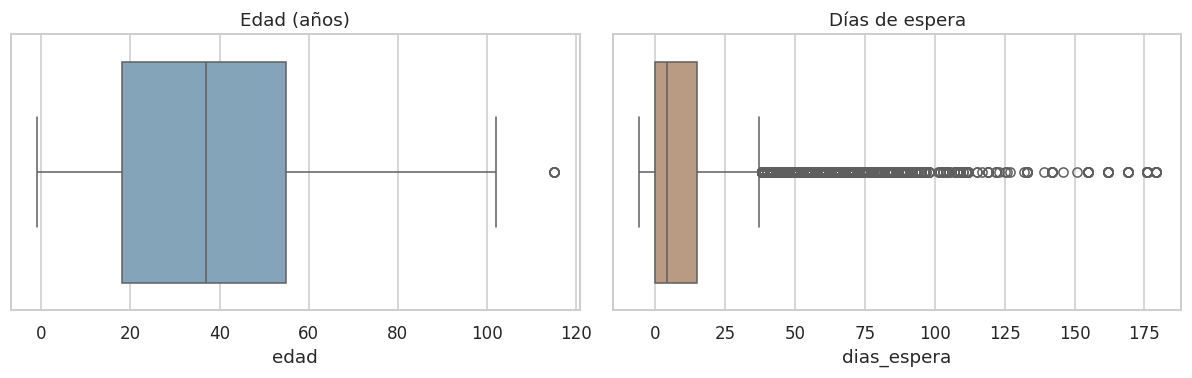

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(x=df.edad, ax=ax[0], color='#7aa6c2'); ax[0].set_title('Edad (años)')
sns.boxplot(x=df.dias_espera, ax=ax[1], color='#c29a7a'); ax[1].set_title('Días de espera')
plt.tight_layout(); plt.savefig(FIGS / 'fig_boxplots.png', bbox_inches='tight'); plt.show()

## 3. Análisis univariado

### 3.1 Variables cuantitativas

In [13]:
def descriptivos(s):
    m = s.mode()
    return {'n': int(s.count()), 'media': s.mean(), 'mediana': s.median(), 'moda': m.iloc[0] if len(m) else np.nan,
            'desv_est': s.std(), 'varianza': s.var(), 'CV_%': s.std() / s.mean() * 100,
            'min': s.min(), 'Q1': s.quantile(.25), 'Q3': s.quantile(.75), 'max': s.max(),
            'rango': s.max() - s.min(), 'asimetria': stats.skew(s), 'curtosis_exceso': stats.kurtosis(s)}

# Variables a nivel de paciente (insumo del clustering)
pac = df.groupby('id_paciente').agg(n_citas=('id_cita', 'count'), n_inasistencias=('inasistencia', 'sum'),
                                    tasa_inasistencia=('inasistencia', 'mean'), espera_media=('dias_espera', 'mean'),
                                    edad=('edad', 'max'))
desc = pd.DataFrame({'edad': descriptivos(df.edad), 'dias_espera': descriptivos(df.dias_espera),
                     'hora_agendamiento': descriptivos(df.hora_agendamiento),
                     'citas_por_paciente': descriptivos(pac.n_citas)}).T
RESULTADOS['descriptivos'] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in desc.to_dict('index').items()}
desc.round(3)

,n,media,mediana,moda,desv_est,varianza,CV_%,min,Q1,Q3,max,rango,asimetria,curtosis_exceso
edad,110527.0,37.089,37.0,0.0,23.110,534.082,62.310,-1.0,18.0,55.0,115.0,116.0,0.122,-0.952
dias_espera,110527.0,10.184,4.0,0.0,15.255,232.715,149.798,-6.0,0.0,15.0,179.0,185.0,2.666,11.797
hora_agendamiento,110527.0,10.775,10.0,7.0,3.216,10.344,29.850,6.0,8.0,13.0,21.0,15.0,0.481,-0.911
citas_por_paciente,62299.0,1.774,1.0,1.0,1.770,3.134,99.785,1.0,1.0,2.0,88.0,87.0,13.765,424.433


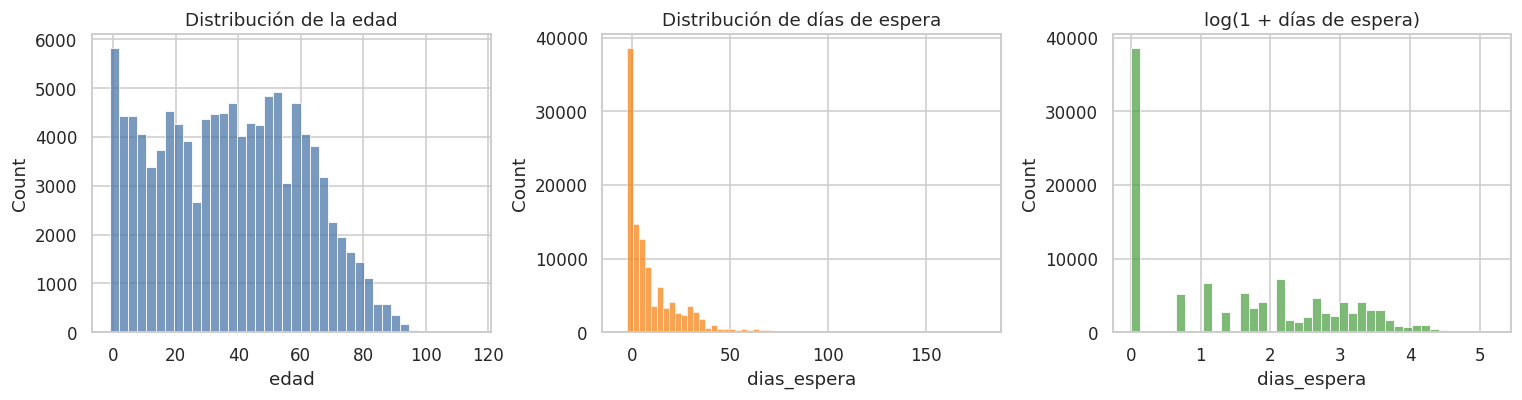

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(df.edad, bins=40, ax=ax[0], color='#4c78a8'); ax[0].set_title('Distribución de la edad')
sns.histplot(df.dias_espera, bins=60, ax=ax[1], color='#f58518'); ax[1].set_title('Distribución de días de espera')
sns.histplot(np.log1p(df.dias_espera.clip(lower=0)), bins=40, ax=ax[2], color='#54a24b'); ax[2].set_title('log(1 + días de espera)')
plt.tight_layout(); plt.savefig(FIGS / 'fig_histogramas.png', bbox_inches='tight'); plt.show()

### 3.2 Variables cualitativas: tablas de frecuencia

In [15]:
cualitativas = ['sexo', 'bolsa_familia', 'hipertension', 'diabetes', 'alcoholismo', 'discapacidad', 'sms_recibido', 'no_asistio', 'dia_semana_cita']
frec = {}
for v in cualitativas:
    t = pd.concat([df[v].value_counts().rename('n'), (df[v].value_counts(normalize=True) * 100).round(2).rename('%')], axis=1)
    frec[v] = {str(k): {'n': int(r['n']), 'pct': float(r['%'])} for k, r in t.iterrows()}
    print(f'--- {v} ---'); print(t, '\n')
RESULTADOS['frecuencias'] = frec
RESULTADOS['tasa_inasistencia_global'] = float(df.inasistencia.mean() * 100)

--- sexo ---
          n     %
sexo             
F     71840  65.0
M     38687  35.0 

--- bolsa_familia ---
                   n      %
bolsa_familia              
0              99666  90.17
1              10861   9.83 

--- hipertension ---
                  n      %
hipertension              
0             88726  80.28
1             21801  19.72 

--- diabetes ---
               n      %
diabetes               
0         102584  92.81
1           7943   7.19 

--- alcoholismo ---
                  n      %
alcoholismo               
0            107167  96.96
1              3360   3.04 

--- discapacidad ---
                   n      %
discapacidad               
0             108286  97.97
1               2042   1.85
2                183   0.17
3                 13   0.01
4                  3   0.00 

--- sms_recibido ---
                  n     %
sms_recibido             
0             75045  67.9
1             35482  32.1 

--- no_asistio ---
                n      %
no_asistio 

In [16]:
top_barrios = df.barrio.value_counts().head(10)
RESULTADOS['top_barrios'] = {k: int(v) for k, v in top_barrios.items()}
RESULTADOS['pct_top10_barrios'] = float(top_barrios.sum() / len(df) * 100)
top_barrios

,count
barrio,
JARDIM CAMBURI,7717
MARIA ORTIZ,5805
RESISTÊNCIA,4431
JARDIM DA PENHA,3877
ITARARÉ,3514
CENTRO,3334
TABUAZEIRO,3132
SANTA MARTHA,3131
JESUS DE NAZARETH,2853


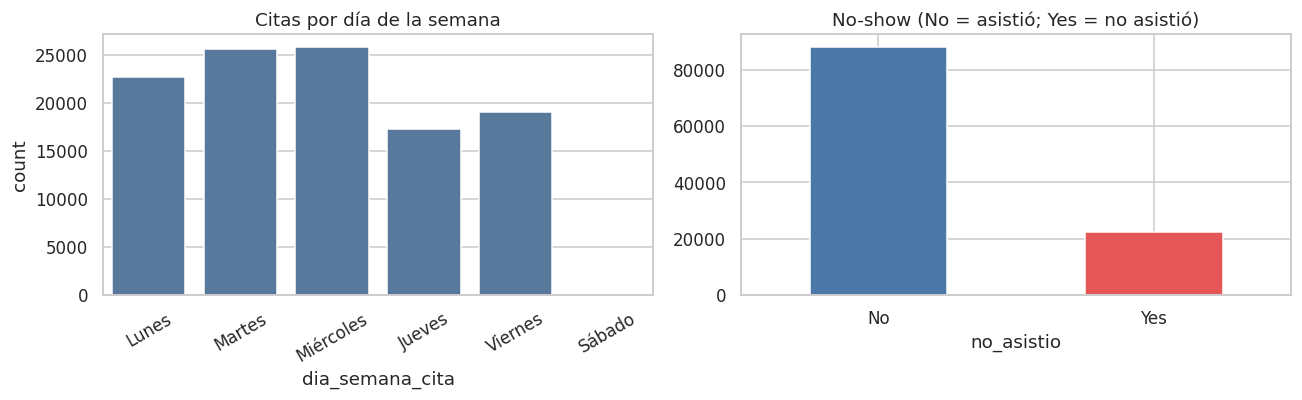

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
orden = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado']
sns.countplot(x='dia_semana_cita', data=df, order=orden, ax=ax[0], color='#4c78a8'); ax[0].set_title('Citas por día de la semana'); ax[0].tick_params(axis='x', rotation=30)
df.no_asistio.value_counts().plot.bar(ax=ax[1], color=['#4c78a8', '#e45756']); ax[1].set_title('No-show (No = asistió; Yes = no asistió)'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig(FIGS / 'fig_frecuencias.png', bbox_inches='tight'); plt.show()

## 4. Análisis bivariado y multivariado

### 4.1 Matrices de correlación (Pearson y Spearman)

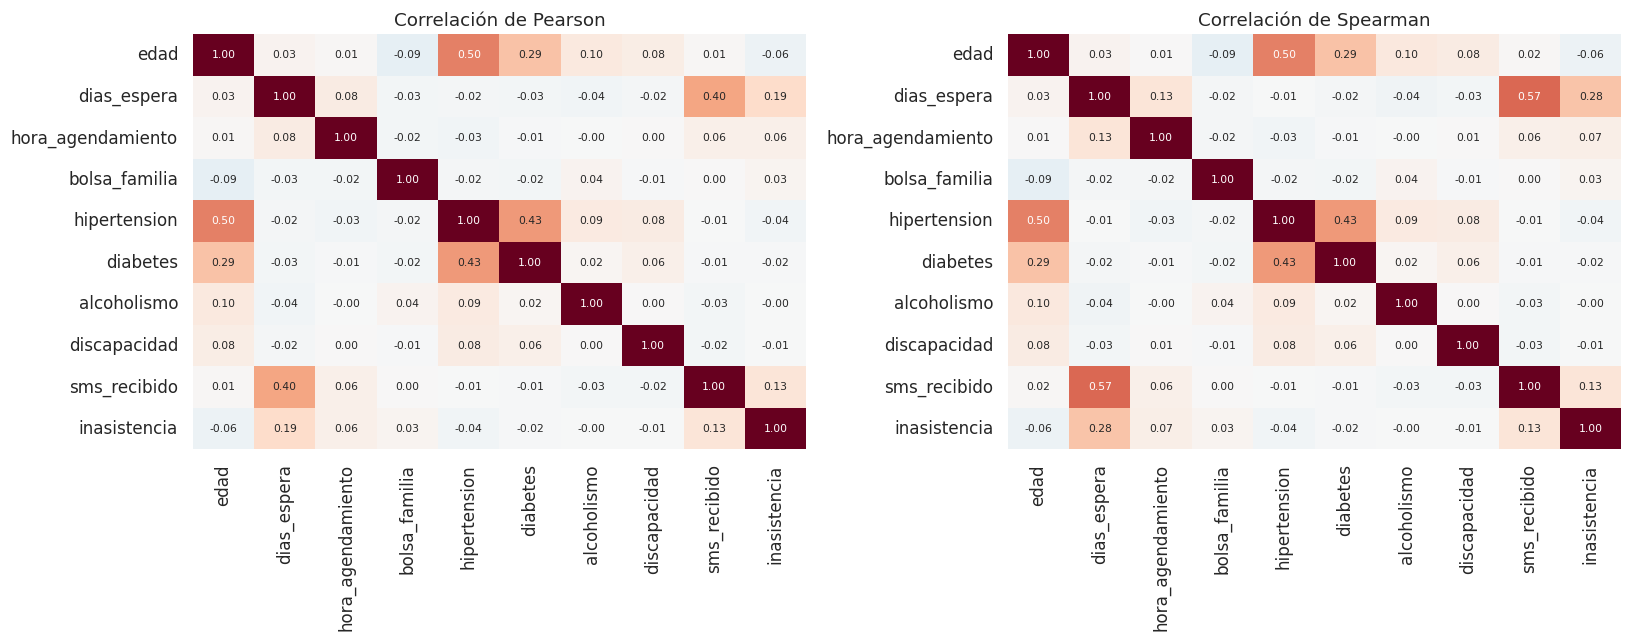

In [18]:
num = df[['edad', 'dias_espera', 'hora_agendamiento', 'bolsa_familia', 'hipertension', 'diabetes', 'alcoholismo', 'discapacidad', 'sms_recibido', 'inasistencia']]
pear = num.corr('pearson'); spear = num.corr('spearman')
RESULTADOS['corr_spearman_inasistencia'] = spear['inasistencia'].drop('inasistencia').round(4).to_dict()
RESULTADOS['corr_pearson_inasistencia'] = pear['inasistencia'].drop('inasistencia').round(4).to_dict()
RESULTADOS['spearman_edad_hipertension'] = float(spear.loc['edad', 'hipertension'])
RESULTADOS['spearman_hipertension_diabetes'] = float(spear.loc['hipertension', 'diabetes'])
RESULTADOS['spearman_sms_espera'] = float(spear.loc['sms_recibido', 'dias_espera'])
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, m, t in [(ax[0], pear, 'Pearson'), (ax[1], spear, 'Spearman')]:
    sns.heatmap(m, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=a, cbar=False, annot_kws={'size': 7})
    a.set_title(f'Correlación de {t}')
plt.tight_layout(); plt.savefig(FIGS / 'fig_correlaciones.png', bbox_inches='tight'); plt.show()

### 4.2 Diagramas de dispersión

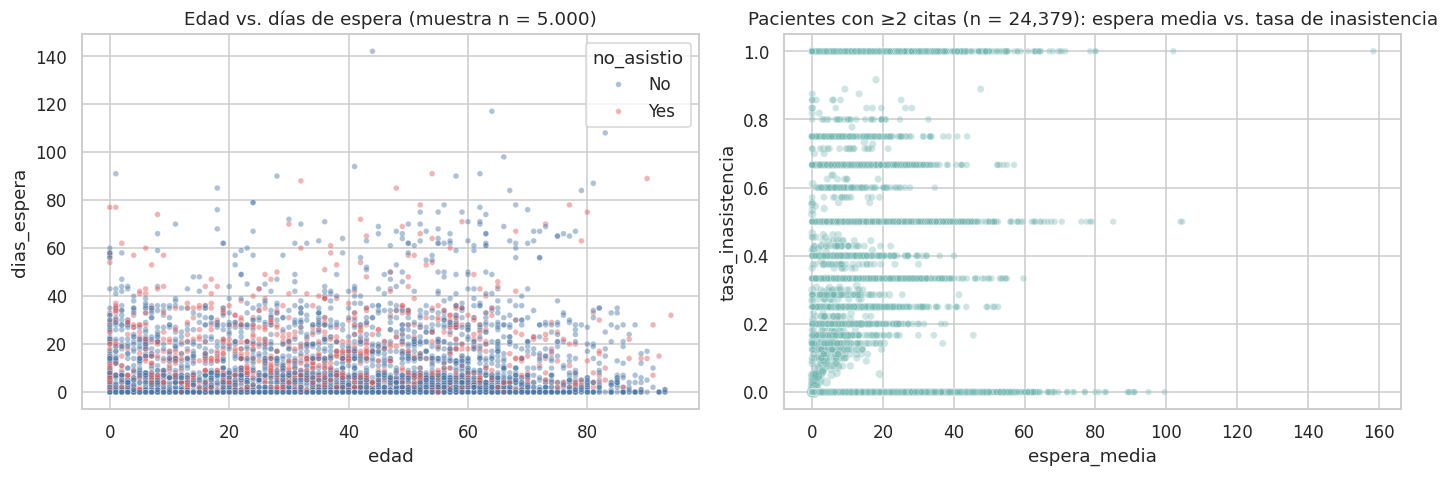

In [19]:
muestra = df.sample(5000, random_state=42)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=muestra, x='edad', y='dias_espera', hue='no_asistio', alpha=.45, s=14, ax=ax[0], palette={'No': '#4c78a8', 'Yes': '#e45756'})
ax[0].set_title('Edad vs. días de espera (muestra n = 5.000)')
pm = pac[pac.n_citas >= 2]
sns.scatterplot(data=pm, x='espera_media', y='tasa_inasistencia', size='n_citas', alpha=.35, ax=ax[1], color='#72b7b2', legend=False)
ax[1].set_title(f'Pacientes con ≥2 citas (n = {len(pm):,}): espera media vs. tasa de inasistencia')
plt.tight_layout(); plt.savefig(FIGS / 'fig_dispersion.png', bbox_inches='tight'); plt.show()
RESULTADOS['pacientes_2mas_citas'] = int(len(pm))

### 4.3 Tasa de inasistencia por categoría y pruebas de independencia χ²

In [20]:
df['espera_cat'] = pd.cut(df.dias_espera, [-np.inf, 0, 7, 30, np.inf], labels=['mismo día', '1-7', '8-30', '>30'])
df['edad_cat'] = pd.cut(df.edad, [-np.inf, 12, 18, 35, 60, np.inf], labels=['0-12', '13-18', '19-35', '36-60', '>60'])
pruebas = []
for v in ['sexo', 'bolsa_familia', 'hipertension', 'diabetes', 'alcoholismo', 'discapacidad', 'sms_recibido', 'dia_semana_cita', 'espera_cat', 'edad_cat']:
    ct = pd.crosstab(df[v], df.no_asistio)
    chi2, p, gl, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); k = min(ct.shape) - 1
    pruebas.append({'variable': v, 'chi2': chi2, 'gl': gl, 'p_valor': p, 'V_Cramer': np.sqrt(chi2 / (n * k)),
                    'decision_5%': 'Dependencia' if p < .05 else 'Independencia'})
chi = pd.DataFrame(pruebas).sort_values('V_Cramer', ascending=False)
RESULTADOS['chi2'] = chi.set_index('variable').to_dict('index')
chi.round(4)

,variable,chi2,gl,p_valor,V_Cramer,decision_5%
8,espera_cat,9568.2678,3,0.0000,0.2942,Dependencia
6,sms_recibido,1766.0677,1,0.0000,0.1264,Dependencia
9,edad_cat,698.8124,4,0.0000,0.0795,Dependencia
2,hipertension,140.6514,1,0.0000,0.0357,Dependencia
1,bolsa_familia,93.5772,1,0.0000,0.0291,Dependencia
7,dia_semana_cita,27.4685,5,0.0000,0.0158,Dependencia
3,diabetes,25.3226,1,0.0000,0.0151,Dependencia
5,discapacidad,7.0346,4,0.1341,0.0080,Independencia
0,sexo,1.8534,1,0.1734,0.0041,Independencia
4,alcoholismo,0.0019,1,0.9654,0.0001,Independencia


In [21]:
tasas = {v: (df.groupby(v, observed=True).inasistencia.mean() * 100).round(2).to_dict() for v in
         ['sexo', 'bolsa_familia', 'hipertension', 'diabetes', 'alcoholismo', 'sms_recibido', 'espera_cat', 'edad_cat', 'dia_semana_cita']}
RESULTADOS['tasas_inasistencia'] = {k: {str(kk): float(vv) for kk, vv in v.items()} for k, v in tasas.items()}
pd.DataFrame(tasas).T

,F,M,0,1,mismo día,1-7,8-30,>30,0-12,13-18,19-35,36-60,>60,Jueves,Lunes,Martes,Miércoles,Sábado,Viernes
sexo,20.31,19.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bolsa_familia,NaN,NaN,19.81,23.74,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hipertension,NaN,NaN,20.90,17.30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diabetes,NaN,NaN,20.36,18.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alcoholismo,NaN,NaN,20.19,20.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sms_recibido,NaN,NaN,16.70,27.57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
espera_cat,NaN,NaN,NaN,NaN,4.66,24.15,31.72,33.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad_cat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.47,26.05,23.83,19.1,15.21,NaN,NaN,NaN,NaN,NaN,NaN
dia_semana_cita,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.35,20.65,20.09,19.69,23.08,21.23


### 4.4 Relación SMS–inasistencia controlando por tiempo de espera
El SMS solo se envía cuando la cita se agenda con anticipación, de modo que la comparación cruda puede estar confundida por la espera. Se estratifica por tramo de espera.

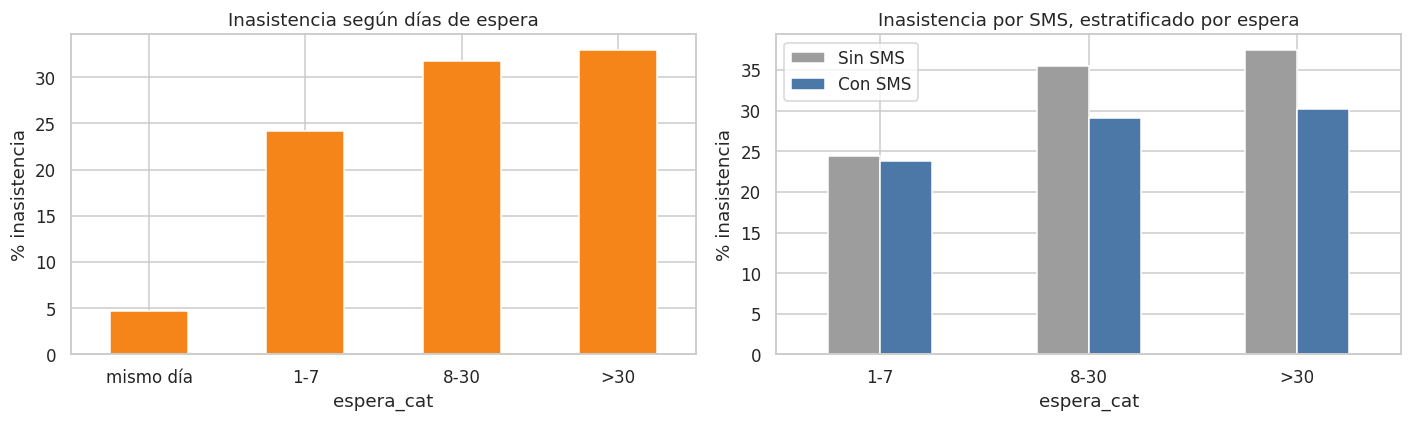

mean         count       
sms_recibido      0      1      0      1
espera_cat                              
1-7           24.36  23.76  20637  11548
8-30          35.55  29.13  11872  17524
>30           37.53  30.20   3968   6410

In [22]:
estr = (df[df.dias_espera > 0].groupby(['espera_cat', 'sms_recibido'], observed=True).inasistencia
        .agg(['mean', 'count']).assign(mean=lambda x: (x['mean'] * 100).round(2)).unstack())
RESULTADOS['sms_estratificado'] = {str(i): {f'sms{c}': float(estr.loc[i, ('mean', c)]) for c in [0, 1]} for i in estr.index}
RESULTADOS['sms_min_espera'] = int(df.loc[df.sms_recibido == 1, 'dias_espera'].min())
RESULTADOS['pct_mismo_dia'] = float((df.dias_espera == 0).mean() * 100)
RESULTADOS['sms_mismo_dia'] = int(df[(df.dias_espera == 0) & (df.sms_recibido == 1)].shape[0])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(df.groupby('espera_cat', observed=True).inasistencia.mean() * 100).plot.bar(ax=ax[0], color='#f58518'); ax[0].set_ylabel('% inasistencia'); ax[0].set_title('Inasistencia según días de espera'); ax[0].tick_params(axis='x', rotation=0)
estr['mean'].plot.bar(ax=ax[1], color=['#9d9d9d', '#4c78a8']); ax[1].set_ylabel('% inasistencia'); ax[1].set_title('Inasistencia por SMS, estratificado por espera'); ax[1].legend(['Sin SMS', 'Con SMS']); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig(FIGS / 'fig_espera_sms.png', bbox_inches='tight'); plt.show()
estr

### 4.5 Diferencias de distribución por condición de asistencia (Mann-Whitney U)

In [23]:
mw = {}
for v in ['edad', 'dias_espera']:
    a, b = df.loc[df.inasistencia == 0, v], df.loc[df.inasistencia == 1, v]
    u, p = stats.mannwhitneyu(a, b)
    mw[v] = {'mediana_asistio': float(a.median()), 'mediana_no_asistio': float(b.median()), 'U': float(u), 'p_valor': float(p)}
RESULTADOS['mann_whitney'] = mw
pd.DataFrame(mw).T

,mediana_asistio,mediana_no_asistio,U,p_valor
edad,38.0,33.0,1.071029e+09,4.152204e-92
dias_espera,2.0,11.0,5.943269e+08,0.000000e+00


## 5. Viabilidad de las tres tareas analíticas

In [24]:
viab = {
  'clasificacion': {'objetivo': 'inasistencia (0/1)', 'balance_%_positivos': round(df.inasistencia.mean() * 100, 2)},
  'regresion': {'objetivo': 'dias_espera', 'valores_unicos': int(df.dias_espera.nunique()), 'rango': [int(df.dias_espera.min()), int(df.dias_espera.max())]},
  'clustering': {'unidad': 'paciente', 'n_pacientes': int(len(pac)), 'variables': ['edad', 'n_citas', 'tasa_inasistencia', 'espera_media', 'n_condiciones_cronicas', 'sms_ratio']},
}
RESULTADOS['viabilidad'] = viab
viab

{'clasificacion': {'objetivo': 'inasistencia (0/1)',
  'balance_%_positivos': np.float64(20.19)},
 'regresion': {'objetivo': 'dias_espera',
  'valores_unicos': 131,
  'rango': [-6, 179]},
 'clustering': {'unidad': 'paciente',
  'n_pacientes': 62299,
  'variables': ['edad',
   'n_citas',
   'tasa_inasistencia',
   'espera_media',
   'n_condiciones_cronicas',
   'sms_ratio']}}

In [25]:
def conv(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return str(o)
(BASE / 'resultados_eda.json').write_text(json.dumps(RESULTADOS, indent=2, ensure_ascii=False, default=conv))
print('Resultados guardados en resultados_eda.json')

Resultados guardados en resultados_eda.json
